# New HSP method based on spike followed by exponential decay.

## Simple "trauma" stimulation on only 10 neurons

INFO       No numerical integration method specified for group 'synapses', using method 'exact' (took 0.01s). [brian2.stateupdaters.base.method_choice]


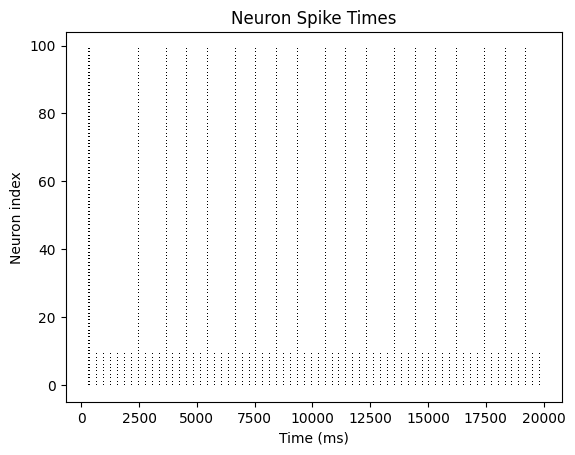

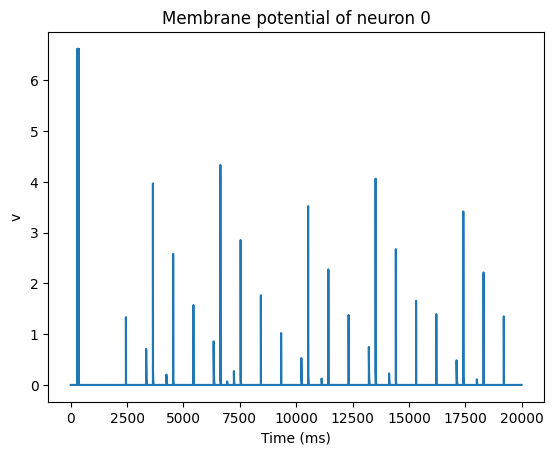

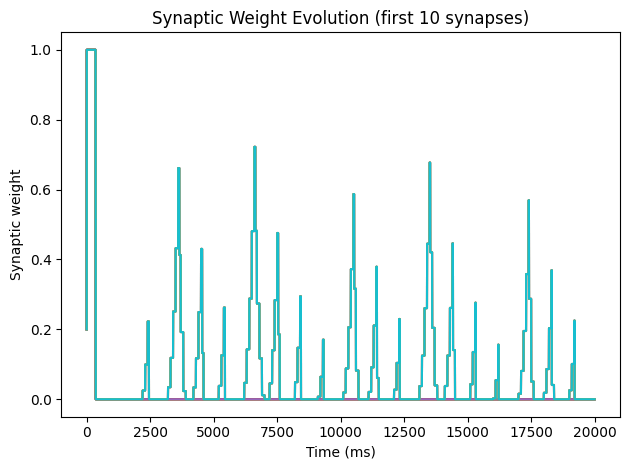

In [1]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# Parameters
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 10000*ms
target_firing_rate = 10 #*Hz
alpha = 0.5

# Neuron model (LIF)
eqs_neurons = '''
dv/dt = (I - v) / tau : 1
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='exact')
neurons.I = 0  
neurons.I[:10] = 1.0000000000001  


# Synapse model with dynamic variable
eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
w : 1
'''

# Synapses
synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='v_post += w',
    on_post='''
        synaptic_activity += 1
        firing_rate_diff = target_firing_rate - synaptic_activity #/ second  
        w += alpha * firing_rate_diff
        w = clip(w, 0, 1)
''')

synapses.connect(p=0.5)
synapses.w = 0.2 #'rand()'
synapses.synaptic_activity = 0

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=10)
weight_mon = StateMonitor(synapses, 'w', record=range(100))  # Track weights of first 100 synapses

# Run
# Add after defining synapses:
synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)
run(20*second)

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0])
plt.title('Membrane potential of neuron 0')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

Different time constante for HSP

WARNING    'w' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 1.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses_4', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


Starting simulation at t=0. s for a duration of 100. s
37.4316 s (37%) simulated in 10s, estimated 17s remaining.
73.062 s (73%) simulated in 20s, estimated 7s remaining.
100. s (100%) simulated in 27s


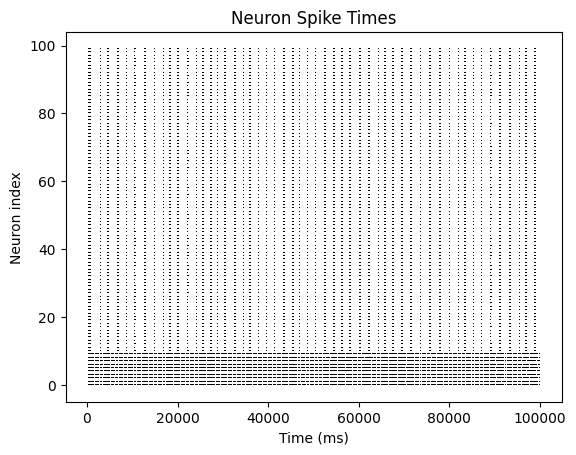

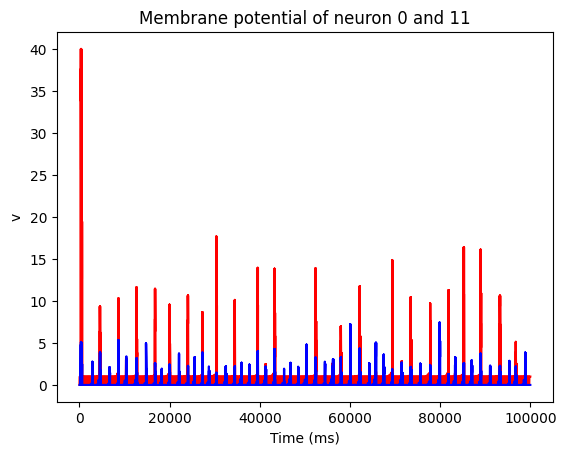

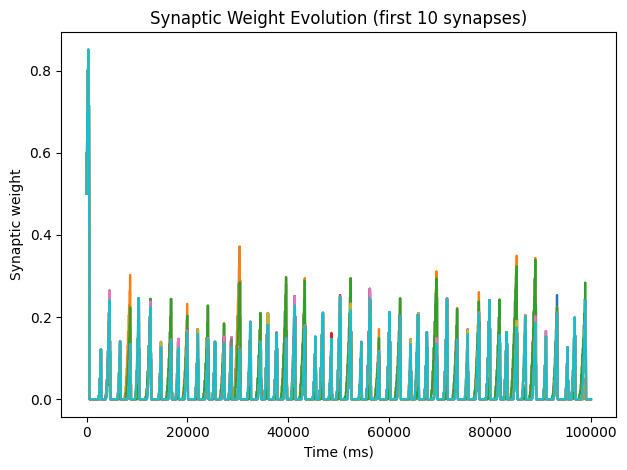

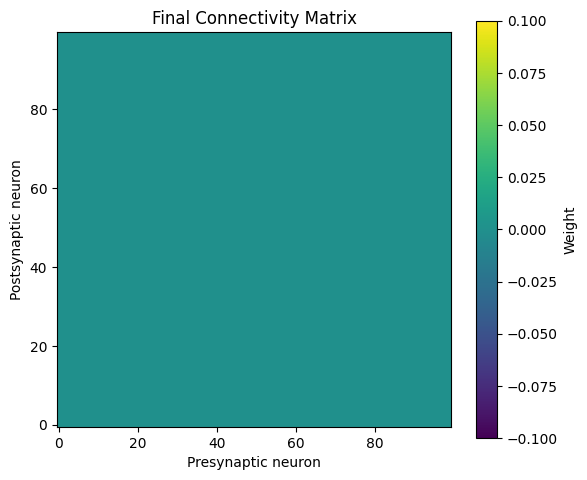

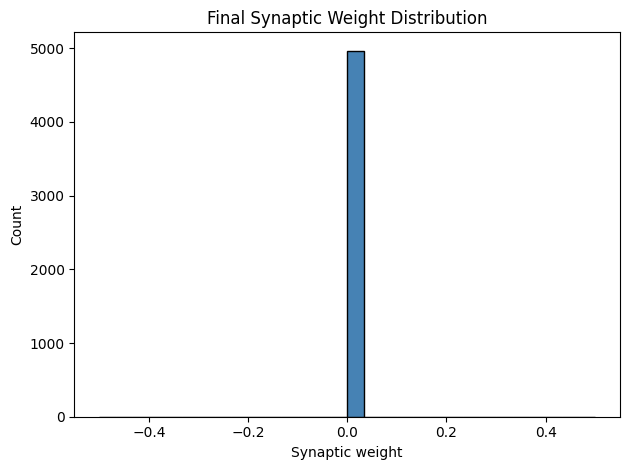

In [12]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# Parameters
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 1000*ms
target_firing_rate = 10 #*Hz
alpha = 0.01

# Neuron model (LIF)
eqs_neurons = '''
dv/dt = (I - v) / tau : 1 
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='exact')
neurons.I = 0  
neurons.I[:10] = 1.000000000001  


# Synapse model with dynamic variable
eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_activity/dt = -pre_activity / tau_homeo : 1 (clock-driven)
w : 1
'''

# Synapses
synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='''
        v_post += w
        pre_activity += 1
    ''',
    on_post='''
        synaptic_activity += 1
    '''
)

synapses.connect(p=0.5)
synapses.w = 0.5 #'0.5 + 0.2*rand()'
synapses.synaptic_activity = 0
synapses.pre_activity = 0

synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,11])
weight_mon = StateMonitor(synapses, 'w', record=range(100))  


run(100*second, report = "text")

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N, N))
for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

# Final weight histogram
plt.figure()
plt.hist(synapses.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

## ADD STDP


In [3]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

time_simu = 1000*second
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 10*second
target_firing_rate = 10 #*Hz
alpha = 0.01

eqs_neurons = '''
dv/dt = (I - v) / tau : 1
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='exact')
neurons.I = 0  
neurons.I[:10] = 1.000000000001  


eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / taupre : 1 (clock-driven)
dpost_trace/dt = -post_trace / taupost : 1 (clock-driven)
taupre : second (constant)
taupost : second (constant)
w : 1
'''


A_plus = 0.01  # potentiation amplitude
A_minus = 0.012  # depression amplitude 

synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='''
        v_post += w
        pre_trace = 1
        w += A_plus * post_trace
        w = clip(w, 0, 1)
    ''',
    on_post='''
        post_trace = 1
        w -= A_minus * pre_trace
        w = clip(w, 0, 1)
        synaptic_activity += 1
    '''
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

synapses.connect(p=0.5)
synapses.w = 0.5 #'0.5 + 0.2*rand()'
synapses.synaptic_activity = 0
synapses.taupre= 20*ms
synapses.taupost = 20*ms
synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,11])
weight_mon = StateMonitor(synapses, 'w', record=range(10))  #100
rate_mon = PopulationRateMonitor(neurons)



run(duration=time_simu, report = 'text')

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N, N))
for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

# Final weight histogram
plt.figure()
plt.hist(synapses.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

WARNING    'w' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value 0.002251695463668444. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses_1', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


Starting simulation at t=0. s for a duration of 1. ks
13.1 s (1%) simulated in 10s, estimated 12m 33s remaining.
16.5813 s (1%) simulated in 20s, estimated 19m 46s remaining.
18.7888 s (1%) simulated in 30s, estimated 26m 7s remaining.
20.9708 s (2%) simulated in 40s, estimated 31m 7s remaining.


KeyboardInterrupt: 

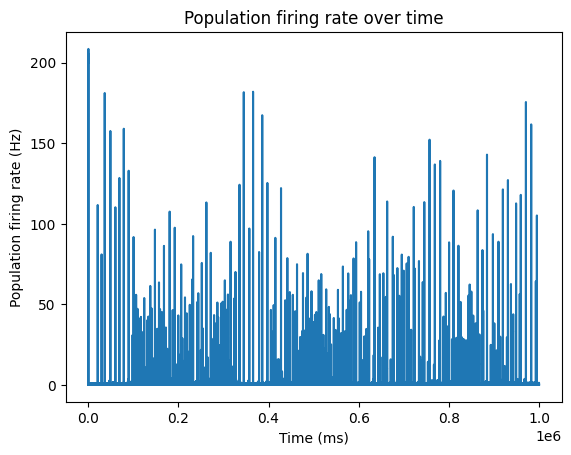

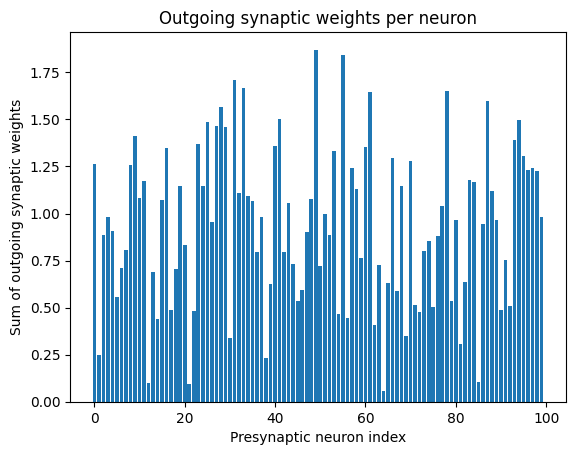

In [ ]:
plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N)
for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
    outgoing_w[i] += w
plt.figure()
plt.bar(np.arange(N), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()


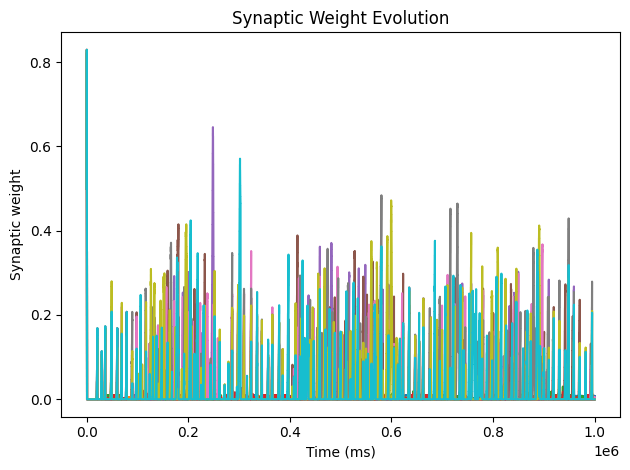

In [ ]:
import matplotlib.pyplot as plt
plt.figure()
for i in range(min(100, len(weight_mon.w))):  
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution')

plt.tight_layout()
plt.show()

Gif time


WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.05346185507319213. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.7. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.7999999999999999. The internal variable will be used. [brian2.groups.group.Group.resolve.re

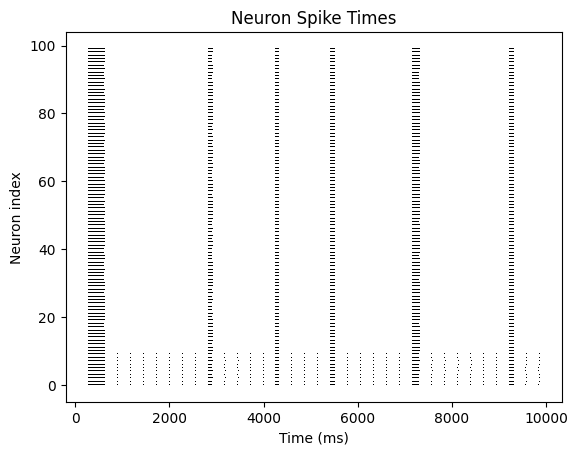

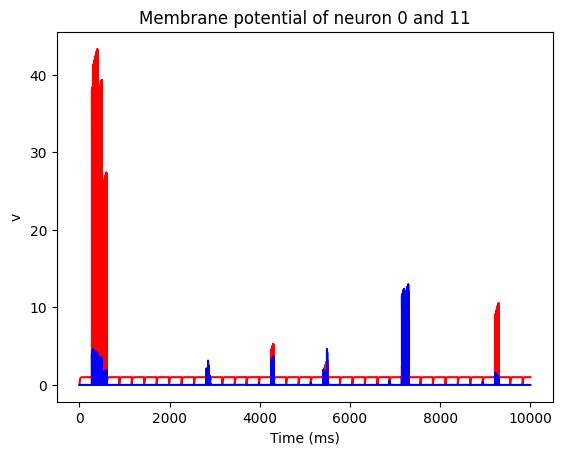

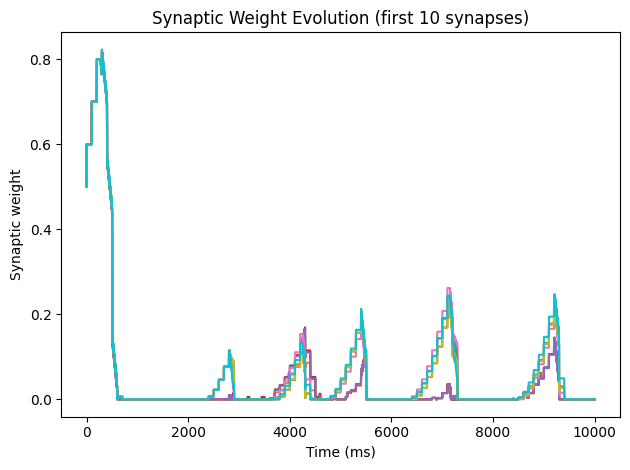

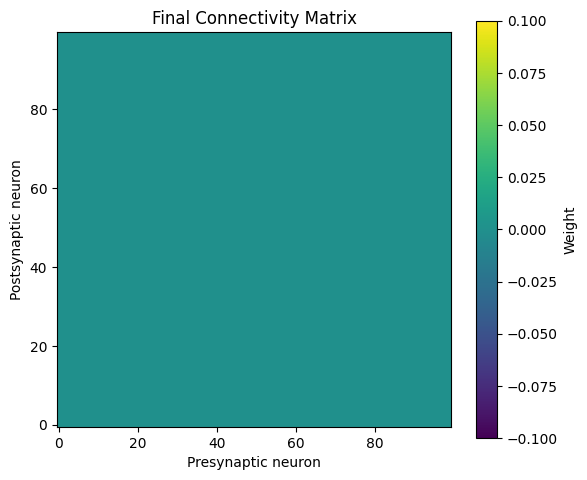

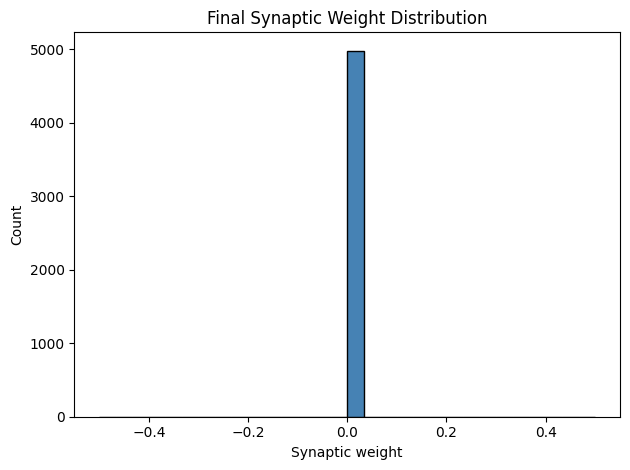

In [ ]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np
import imageio
import os

start_scope()

# Parameters
time_simu = 10*second
save_interval = 0.01*second   
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 1*second
target_firing_rate = 10
alpha = 0.01

eqs_neurons = '''
dv/dt = (I - v) / tau : 1
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='exact')
neurons.I = 0
neurons.I[:10] = 1.000000000001

eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / taupre : 1 (clock-driven)
dpost_trace/dt = -post_trace / taupost : 1 (clock-driven)
taupre : second (constant)
taupost : second (constant)
w : 1
'''

A_plus = 0.01
A_minus = 0.012

synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='''
        v_post += w
        pre_trace = 1
        w += A_plus * post_trace
        w = clip(w, 0, 1)
    ''',
    on_post='''
        post_trace = 1
        w -= A_minus * pre_trace
        w = clip(w, 0, 1)
        synaptic_activity += 1
    '''
)

synapses.connect(p=0.5)
synapses.w = 0.5
synapses.synaptic_activity = 0
synapses.taupre = 20*ms
synapses.taupost = 20*ms

synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0, 11])
weight_mon = StateMonitor(synapses, 'w', record=range(10))
rate_mon = PopulationRateMonitor(neurons)

n_saves = int(time_simu / save_interval)
conn_matrices = []
image_files = []

for snap in range(n_saves):
    run(save_interval)
    conn_matrix = np.zeros((N, N))
    for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
        conn_matrix[i, j] = w
    conn_matrices.append(conn_matrix.copy())
    # Plot and save image
    plt.figure(figsize=(5, 4))
    plt.imshow(conn_matrix, cmap='viridis', origin='lower', vmin=0, vmax=1)
    plt.colorbar(label='Weight')
    plt.title(f'Connectivity at t={((snap+1)*float(save_interval/second)):.0f}s')
    plt.xlabel('Presynaptic neuron')
    plt.ylabel('Postsynaptic neuron')
    plt.tight_layout()
    img_name = f'conn_matrix_{snap:03d}.png'
    plt.savefig(img_name)
    plt.close()
    image_files.append(img_name)

# Make gif
with imageio.get_writer('connectivity_evolution.gif', mode='I', duration=5.0) as writer:
    for filename in image_files:
        image = imageio.imread(filename)
        writer.append_data(image)

for fname in image_files:
    os.remove(fname)



plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0], color='red')
plt.plot(statemon.t/ms, statemon.v[1], color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

plt.figure()
for i in range(min(10, len(weight_mon.w))):
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
final_matrix = conn_matrices[-1]
plt.imshow(final_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

plt.figure()
plt.hist(synapses.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()


Problems : too much synchrony, too sensitive (very unstable). So need to change the input stimulation.

Stimu : poisson all neurons

Withdrawal seizure with STPD

WARNING    'w' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value 0.4265509847760176. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 100. s
23.0434 s (23%) simulated in 10s, estimated 33s remaining.
46.4755 s (46%) simulated in 20s, estimated 23s remaining.
75.6538 s (75%) simulated in 30s, estimated 10s remaining.
99.0153 s (99%) simulated in 40s, estimated < 1s remaining.
100. s (100%) simulated in 40s


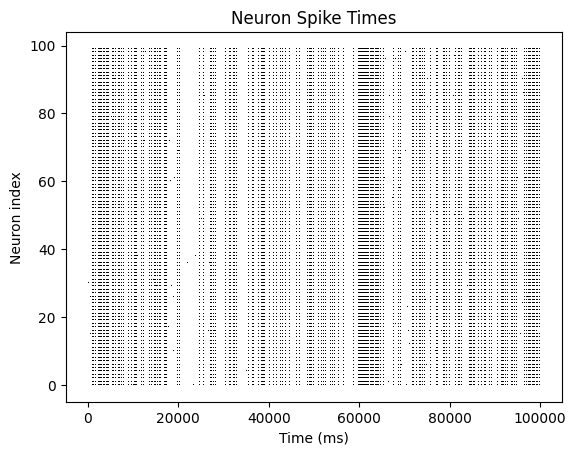

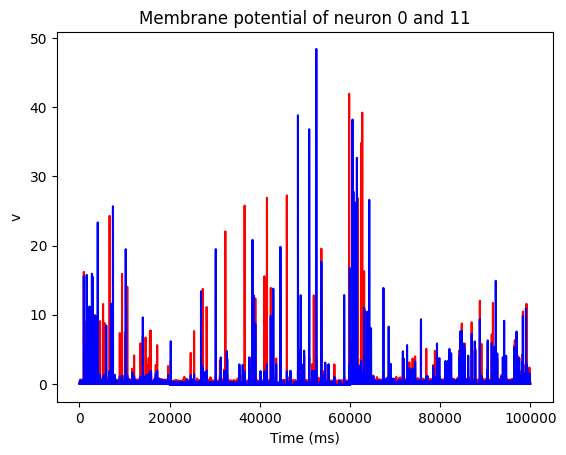

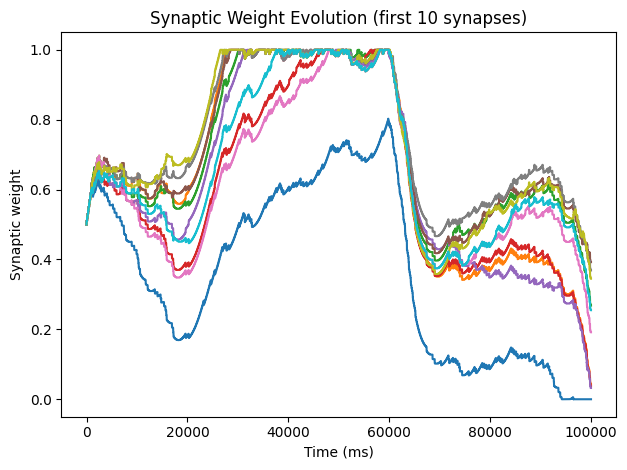

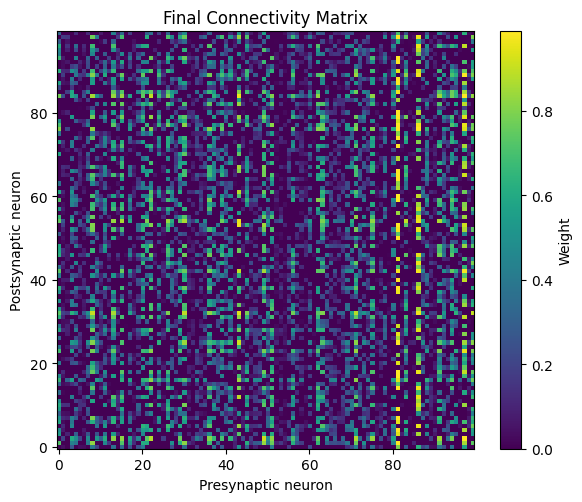

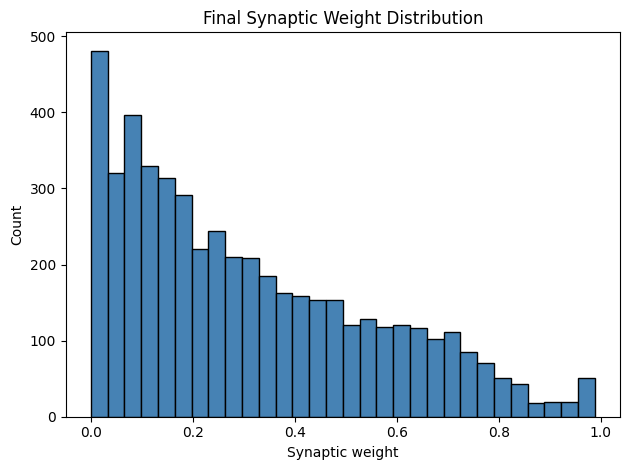

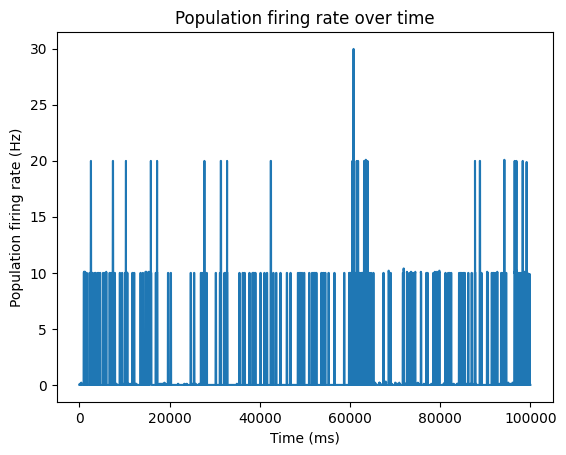

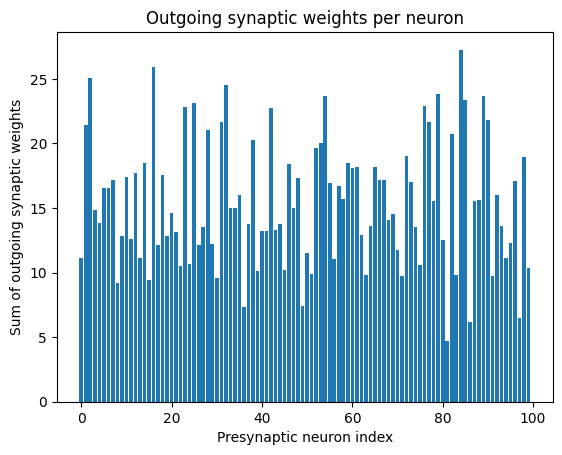

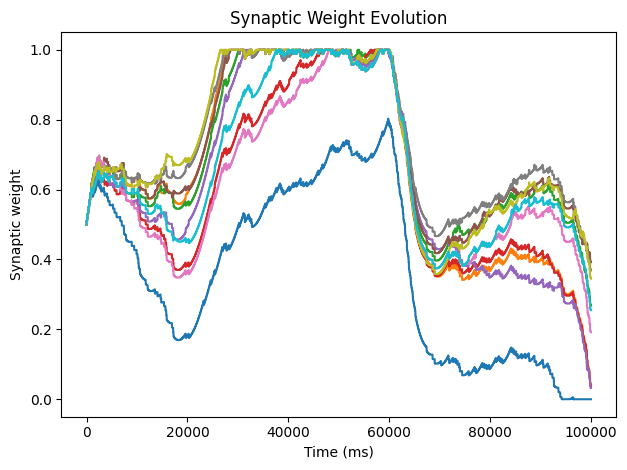

In [ ]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

time_simu = 100*second
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 5*second
target_firing_rate = 10 #*Hz
alpha = 0.001
stim_N = N
stim_rate = 5*Hz


# alcohol‐withdrawal current window
t_on       = 20*second
t_off      = 60*second
I_bg       = -0.15

eqs_neurons = '''
dv/dt = (I - v + I_bg_dyn) / tau : 1 (unless refractory)
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : 1 (shared)
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='euler')
neurons.I = 0  

# Poisson input to first stim_N neurons
poisson_input = PoissonGroup(stim_N, rates=stim_rate)
input_syn = Synapses(poisson_input, neurons,'w_in : 1', on_pre='v_post += w_in')
input_syn.connect(j='i')
input_syn.w_in = '0.3 + 0.4*rand()'



eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / tau_pre : 1 (clock-driven)
dpost_trace/dt = -post_trace / tau_post : 1 (clock-driven)
w : 1
'''


A_plus = 0.01  # potentiation amplitude
A_minus = 0.012  # depression amplitude 
tau_pre = 20*ms
tau_post = 20*ms

synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='''
        v_post += w
        pre_trace = 1
        w += A_plus * post_trace
        w = clip(w, 0, 1)
    ''',
    on_post='''
        post_trace = 1
        w -= A_minus * pre_trace
        w = clip(w, 0, 1)
        synaptic_activity += 1
    '''
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

synapses.connect(p=0.5)
synapses.w = 0.5 #'0.5 + 0.2*rand()'
synapses.synaptic_activity = 0

synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,11])
weight_mon = StateMonitor(synapses, 'w', record=range(10))  #100
rate_mon = PopulationRateMonitor(neurons)


run(duration=time_simu, report = 'text')

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N, N))
for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

# Final weight histogram
plt.figure()
plt.hist(synapses.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N)
for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
    outgoing_w[i] += w
plt.figure()
plt.bar(np.arange(N), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()

plt.figure()
for i in range(min(100, len(weight_mon.w))):  
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution')

plt.tight_layout()
plt.show()

Too much synchrony, add randomness in Tau and poisson weights, stimulate 30 neurons and change every 10sec. 

Add inhibitory neurons.

WARNING    'w' is an internal variable of group 'synapses_3', but also exists in the run namespace with the value 0.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 100. s
14.4893 s (14%) simulated in 10s, estimated 59s remaining.
19.3951 s (19%) simulated in 20s, estimated 1m 23s remaining.
22.9155 s (22%) simulated in 30s, estimated 1m 41s remaining.
27.1878 s (27%) simulated in 40s, estimated 1m 47s remaining.
30.1975 s (30%) simulated in 50s, estimated 1m 56s remaining.
39.9029 s (39%) simulated in 1m 0s, estimated 1m 30s remaining.
54.9667 s (54%) simulated in 1m 10s, estimated 57s remaining.
66.6168 s (66%) simulated in 1m 20s, estimated 40s remaining.
73.6277 s (73%) simulated in 1m 30s, estimated 32s remaining.
78.6245 s (78%) simulated in 1m 40s, estimated 27s remaining.
82.2767 s (82%) simulated in 1m 50s, estimated 24s remaining.
86.3928 s (86%) simulated in 2m 0s, estimated 19s remaining.
95.6019 s (95%) simulated in 2m 10s, estimated 6s remaining.
100. s (100%) simulated in 2m 13s


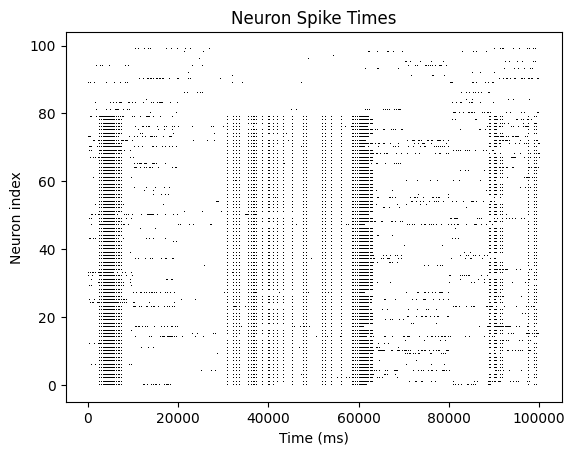

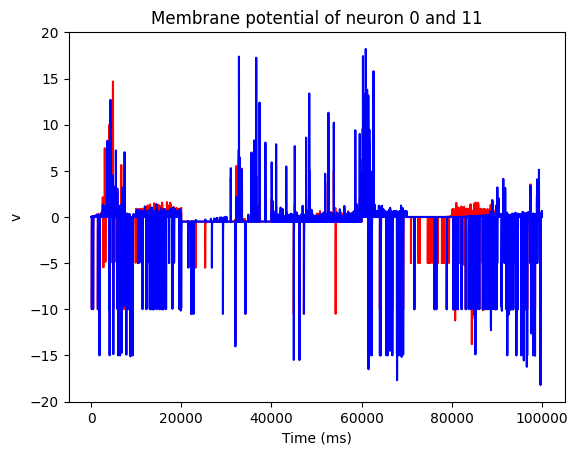

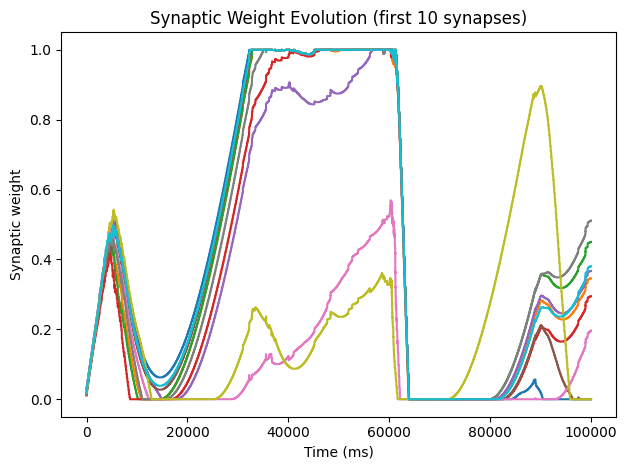

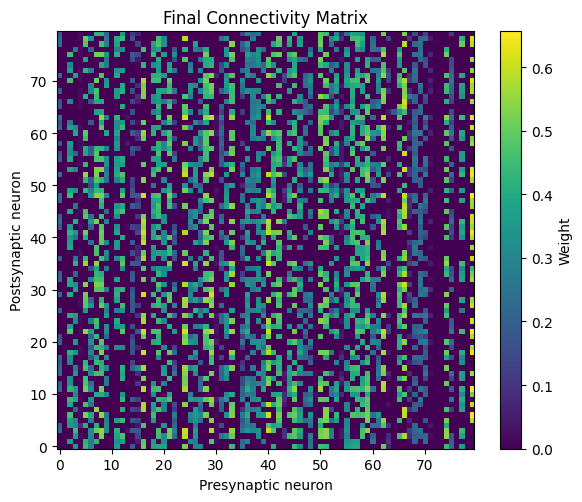

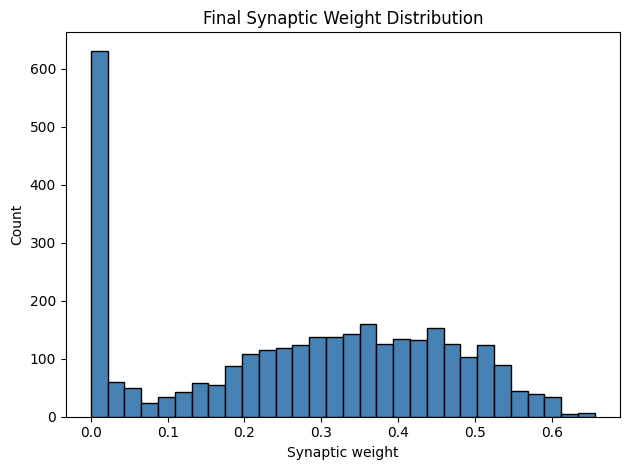

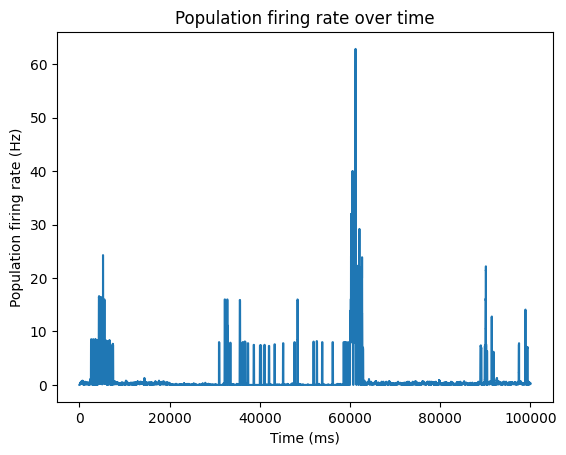

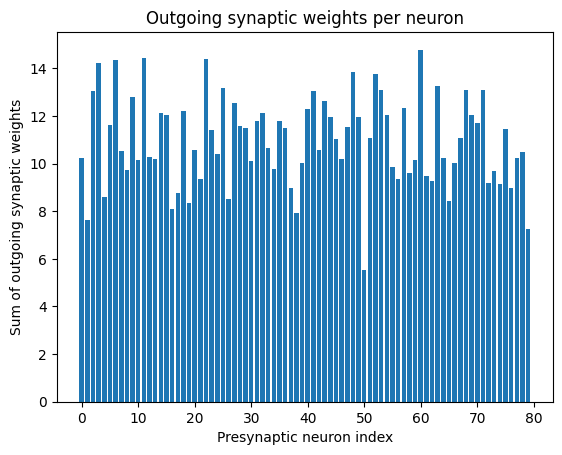

<Figure size 640x480 with 0 Axes>

In [ ]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

time_simu = 100*second
tau_n = '10*ms + 5*ms*rand()' #10*ms
refractory_period = 5*ms
tau_homeo = 10*second
target_firing_rate = 10 
alpha = 0.001
stim_N = 30
stim_rate = 10*Hz
change_interval = 10*second
n_steps = int(time_simu/change_interval)


# alcohol‐withdrawal current window
t_on       = 20*second
t_off      = 60*second
I_bg       = -0.5

eqs_neurons = '''
dv/dt = (I - v + I_bg_dyn) / tau : 1 (unless refractory)
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : 1 (shared)
I : 1
tau : second
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = rand()*0.1',
                      refractory=refractory_period, method='euler')
neurons.I = 0  
neurons.tau = tau_n


poisson_input = PoissonGroup(N, rates=0*Hz)
input_syn = Synapses(poisson_input, neurons,'w_in : 1', on_pre='v_post += w_in')
input_syn.connect(j='i')
input_syn.w_in = '0.5 + 0.4*rand()'

stim_targets = [np.random.choice(N, stim_N, replace=False) for _ in range(n_steps)]
current_step = 0

@network_operation(dt=change_interval)
def update_poisson_rates():
    global current_step
    rates = np.zeros(N) * Hz      
    rates[stim_targets[current_step]] = stim_rate
    poisson_input.rates = rates   
    current_step += 1
    if current_step >= n_steps:
        current_step = n_steps - 1


N_e = 80  # excitatory
N_i = 20  # inhibitory
N = N_e + N_i

eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / tau_pre : 1 (clock-driven)
dpost_trace/dt = -post_trace / tau_post : 1 (clock-driven)
w : 1
'''


A_plus = 0.01  # potentiation amplitude
A_minus = 0.012  # depression amplitude 
tau_pre = 20*ms
tau_post = 20*ms

exc_syn = Synapses(neurons[:N_e], neurons[:N_e], model=eqs_syn,
    on_pre='''
        v_post += w
        pre_trace += 1
        w += A_plus * post_trace
        w = clip(w, 0, 1)
    ''',
    on_post='''
        post_trace += 1
        w -= A_minus * pre_trace
        w = clip(w, 0, 1)
        synaptic_activity += 1
    ''',
    delay=rand()*2*ms
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

exc_syn.connect(p=0.5)
exc_syn.w = '0.01 + 0.02*rand()'
exc_syn.synaptic_activity = 0

exc_syn.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)

# Inhibitory synapses
inh_syn = Synapses(neurons[N_e:], neurons[:N_e], 'w_inh : 1', on_pre='v_post -= w_inh')
inh_syn.connect(p=0.5)
inh_syn.w_inh = 10.0  
inh_syn.delay = rand()*2*ms

# Optionally, connect inhibition to all neurons
inh_syn_all = Synapses(neurons[N_e:], neurons, 'w_inh_all : 1', on_pre='v_post -= w_inh_all')
inh_syn_all.connect(p=0.2)
inh_syn_all.w_inh_all = 5.0
inh_syn_all.delay = rand()*2*ms


# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,11])
weight_mon = StateMonitor(exc_syn, 'w', record=range(10))  #100
rate_mon = PopulationRateMonitor(neurons)

run(duration=time_simu, report = 'text')

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N_e, N_e))
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

# Final weight histogram
plt.figure()
plt.hist(exc_syn.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N_e)
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    outgoing_w[i] += w
plt.figure()
plt.bar(np.arange(N_e), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()

plt.tight_layout()
plt.show()

Gif, w_max, make taupre and taupost STDP constant.

WARNING    'i' is an internal variable of group 'synapses_3', but also exists in the run namespace with the value 79. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'j' is an internal variable of group 'synapses', but also exists in the run namespace with the value 78. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 2.2540373269817555e-34. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


Starting simulation at t=0. s for a duration of 150. s
13.6934 s (9%) simulated in 10s, estimated 1m 40s remaining.
25.8787 s (17%) simulated in 20s, estimated 1m 36s remaining.
31.6486 s (21%) simulated in 30s, estimated 1m 52s remaining.
36.7992 s (24%) simulated in 40s, estimated 2m 3s remaining.
41.4186 s (27%) simulated in 50s, estimated 2m 11s remaining.
46.6715 s (31%) simulated in 1m 0s, estimated 2m 13s remaining.
51.7224 s (34%) simulated in 1m 10s, estimated 2m 13s remaining.
56.0175 s (37%) simulated in 1m 20s, estimated 2m 14s remaining.
59.791 s (39%) simulated in 1m 30s, estimated 2m 16s remaining.
63.8367 s (42%) simulated in 1m 40s, estimated 2m 15s remaining.
67.3833 s (44%) simulated in 1m 50s, estimated 2m 15s remaining.
70.585 s (47%) simulated in 2m 0s, estimated 2m 15s remaining.
74.2275 s (49%) simulated in 2m 10s, estimated 2m 13s remaining.
77.9441 s (51%) simulated in 2m 20s, estimated 2m 9s remaining.
81.2299 s (54%) simulated in 2m 30s, estimated 2m 7s rema

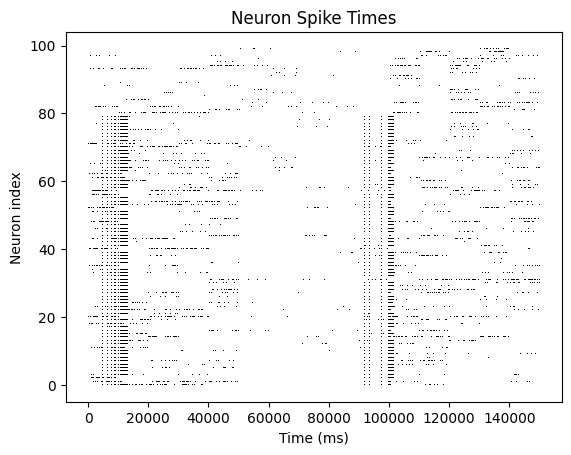

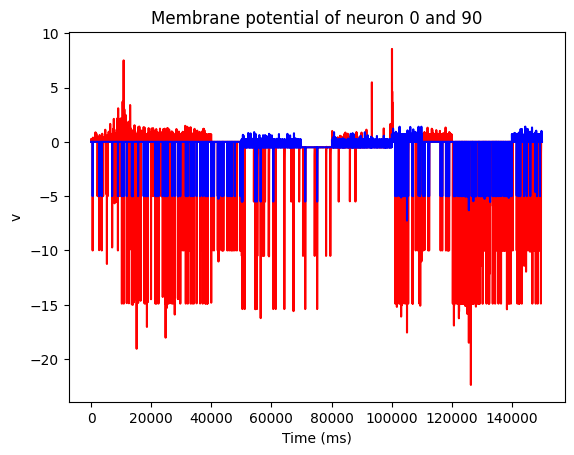

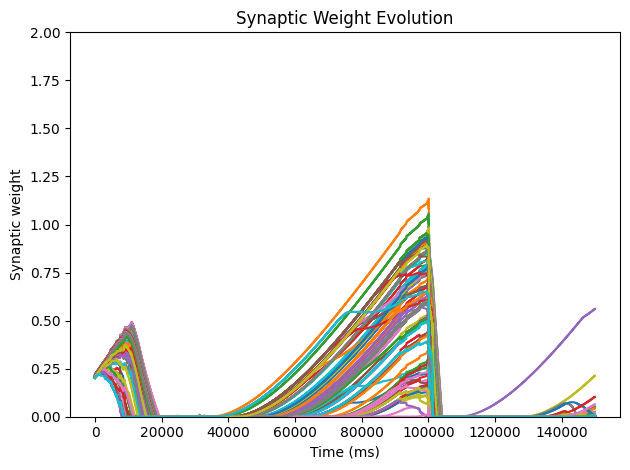

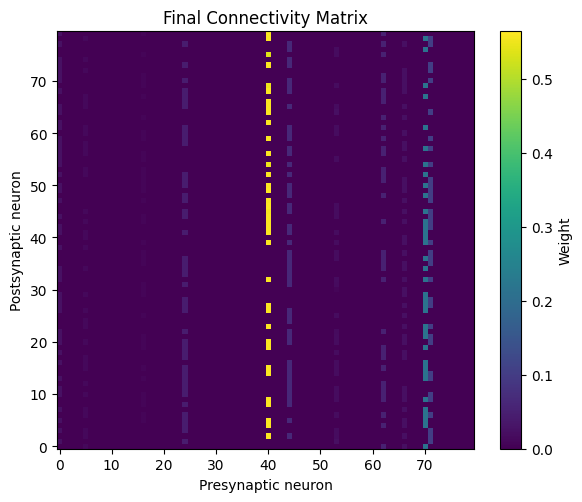

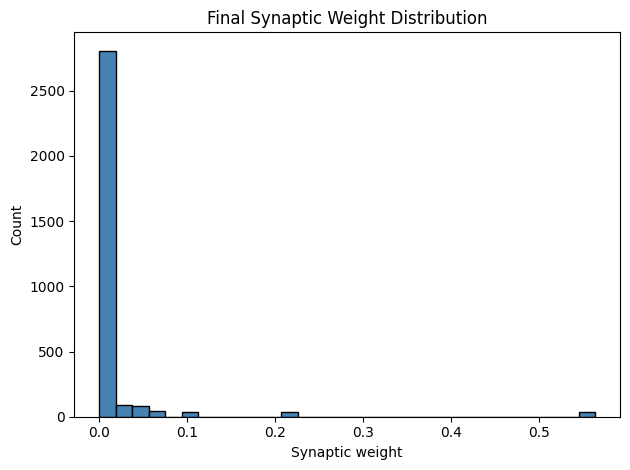

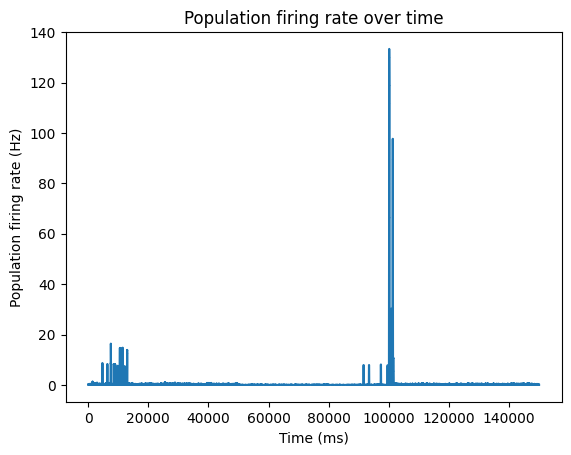

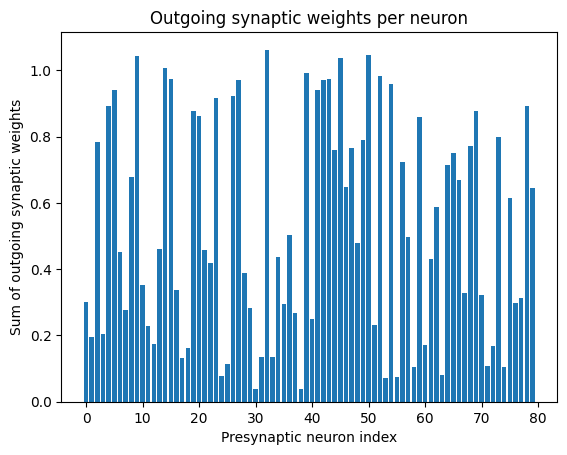

<Figure size 640x480 with 0 Axes>

In [6]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np
import imageio
import os


start_scope()

time_simu = 150*second
save_interval = 0.1*second   
tau_n = '10*ms + 5*ms*rand()' #10*ms
refractory_period = 5*ms
tau_homeo = 20*second
target_firing_rate = 5
alpha = 0.0005
stim_N = 30
stim_rate = 10*Hz
change_interval = 10*second
n_steps = int(time_simu/change_interval)
w_max=2

# alcohol‐withdrawal current window
t_on       = 50*second
t_off      = 100*second
I_bg       = -0.50

eqs_neurons = '''
dv/dt = (I - v + I_bg_dyn) / tau : 1 (unless refractory)
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : 1 (shared)
I : 1
tau : second
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = rand()*0.1',
                      refractory=refractory_period, method='euler')
neurons.I = 0  
neurons.tau = tau_n


poisson_input = PoissonGroup(N, rates=0*Hz)
input_syn = Synapses(poisson_input, neurons,'w_in : 1', on_pre='v_post += w_in')
input_syn.connect(j='i')
input_syn.w_in = '0.5 + 0.4*rand()'

stim_targets = [np.random.choice(N, stim_N, replace=False) for _ in range(n_steps)]
current_step = 0

@network_operation(dt=change_interval)
def update_poisson_rates():
    global current_step
    rates = np.zeros(N) * Hz      
    rates[stim_targets[current_step]] = stim_rate
    poisson_input.rates = rates   
    current_step += 1
    if current_step >= n_steps:
        current_step = n_steps - 1


N_e = 80  # excitatory
N_i = 20  # inhibitory
N = N_e + N_i

eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / taupre : 1 (clock-driven)
dpost_trace/dt = -post_trace / taupost : 1 (clock-driven)
taupre : second (constant)
taupost : second (constant)
w : 1
'''


A_plus = 0.01  # potentiation amp
A_minus = 0.012  # depression amp

exc_syn = Synapses(neurons[:N_e], neurons[:N_e], model=eqs_syn,
    on_pre='''
        v_post += w
        pre_trace += 1
        w += A_plus * post_trace
        w = clip(w, 0, w_max)
    ''',
    on_post='''
        post_trace += 1
        w -= A_minus * pre_trace
        w = clip(w, 0, w_max)
        synaptic_activity += 1
    ''',
    delay=rand()*2*ms
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

exc_syn.connect('i != j', p=0.5)
exc_syn.w = '0.2 + 0.02*rand()'
exc_syn.synaptic_activity = 0
exc_syn.taupre = 20*ms
exc_syn.taupost = 20*ms

exc_syn.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, w_max)
''', dt=100*ms)

# Inhibitory synapses
inh_syn = Synapses(neurons[N_e:], neurons[:N_e], 'w_inh : 1', on_pre='v_post -= w_inh')
inh_syn.connect(p=0.5)
inh_syn.w_inh = 10.0  
inh_syn.delay = rand()*2*ms

# Optionally, connect inhibition to all neurons
inh_syn_all = Synapses(neurons[N_e:], neurons, 'w_inh_all : 1', on_pre='v_post -= w_inh_all')
inh_syn_all.connect(p=0.3)
inh_syn_all.w_inh_all = 5.0
inh_syn_all.delay = rand()*2*ms


# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,90])
weight_mon = StateMonitor(exc_syn, 'w', record=range(100))  #100
rate_mon = PopulationRateMonitor(neurons)

run(time_simu, report = "text")

# n_saves = int(time_simu / save_interval)
# conn_matrices = []
# image_files = []

# for snap in range(n_saves):
#     run(save_interval)
#     conn_matrix = np.zeros((N_e, N_e))
#     for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
#         conn_matrix[i, j] = w
#     conn_matrices.append(conn_matrix.copy())
#     # Plot and save image
#     plt.figure(figsize=(5, 4))
#     plt.imshow(conn_matrix, cmap='viridis', origin='lower', vmin=0, vmax=1)
#     plt.colorbar(label='Weight')
#     plt.title(f'Connectivity at t={((snap+1)*float(save_interval/second)):.0f}s')
#     plt.xlabel('Presynaptic neuron')
#     plt.ylabel('Postsynaptic neuron')
#     plt.tight_layout()
#     img_name = f'conn_matrix_{snap:03d}.png'
#     plt.savefig(img_name)
#     plt.close()
#     image_files.append(img_name)

# # Make gif
# with imageio.get_writer('connectivity_evolution_HP_HL_AWS_alpha_0001.gif', mode='I', duration=5.0) as writer:
#     for filename in image_files:
#         image = imageio.imread(filename)
#         writer.append_data(image)

# for fname in image_files:
#     os.remove(fname)


# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 90')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(100, len(weight_mon.w))):  
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution')
plt.ylim(0, w_max)

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N_e, N_e))
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

# Final weight histogram
plt.figure()
plt.hist(exc_syn.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N_e)
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    outgoing_w[i] += w
plt.figure()
plt.bar(np.arange(N_e), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()

plt.tight_layout()
plt.show()